In [1]:
import sys
sys.path.append('..')
import matplotlib.pyplot as plt
import shap
from src import models

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## load data + features

same pipeline as the eda notebook (filter residential, trim outliers) plus the hex/distance/trailing features from `features.py`.

In [2]:
df = models.load_dataset()
df.shape

(240869, 32)

## model comparison

linear regression, gam (factor terms on property attrs, smooth terms on distance + hex features), xgboost (hyperparameters tuned via spatial-cv search), and lightgbm. all scored on log10(price) with 5-fold spatial block cv (grouped by coarse hex, not random k-fold -- see `spatial_diagnostics.py`).

feature set is the full research set from `PLAN.md`'s improvement audit: baseline property/date features (including a cyclical month encoding and an sdlt-rush flag), the original hex trailing price/count/neighbour-lag, a finer res-9 hex trend, a shrinkage-smoothed hex target encoding, and street/named-property features. the last of those needs a specific street/house, not just a postcode, so it's research-only -- the deployed `predict.py` tool uses a smaller "serving" subset (`models.SERVING_NUMERIC`), see `03_predict.ipynb`.

In [3]:
results = models.compare_models(df)
results

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/scipy/linalg/_basic.py:1449: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T


... (4 outputs left out)

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,rmse,mae,r2
linear,0.155070,0.113284,0.629929
gam,0.153135,0.110883,0.637849
xgboost,0.146775,0.105467,0.667877
lightgbm,0.146990,0.105833,0.666956


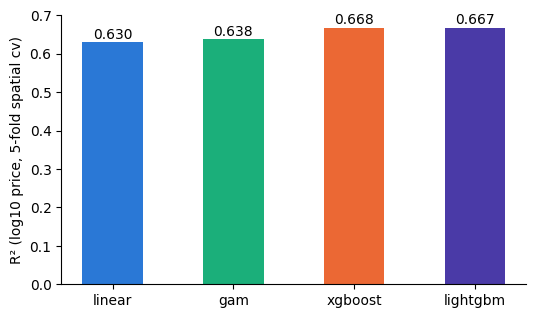

In [4]:
colors = {"linear": "#2a78d6", "gam": "#1baf7a", "xgboost": "#eb6834", "lightgbm": "#4a3aa7"}
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(results.index, results["r2"], color=[colors[m] for m in results.index], width=0.5)
ax.set_ylabel("R² (log10 price, 5-fold spatial cv)")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(results["r2"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

xgboost and lightgbm are essentially tied, both ahead of gam and linear -- but the gap between *all four* is still modest next to how far all of them are from perfect. most of the lift over the original baseline came from features (multi-resolution hex, target encoding, street-level data), not from swapping model classes -- confirmed directly in `PLAN.md`'s improvement audit, where hyperparameter tuning and trying lightgbm both moved R² by less than the cheapest feature addition did.

## moran's i on residuals: baseline vs hex features

residuals are out-of-fold predictions from the spatial cv, not in-sample -- an in-sample fit understates residual autocorrelation because the model has already absorbed local structure. `baseline` uses property attributes + distance-to-centre only; `hex features` adds hex trailing price/count and the neighbour lag.

In [5]:
moran_df = models.moran_before_after(df)
moran_df

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/

('WARNING: ', '88195d344bfffff', ' is an island (no neighbors)')
('WARNING: ', '88195d344bfffff', ' is an island (no neighbors)')


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There i

,moran_i,p_sim
baseline (no hex features),0.723712,0.001
hex features,0.478424,0.001


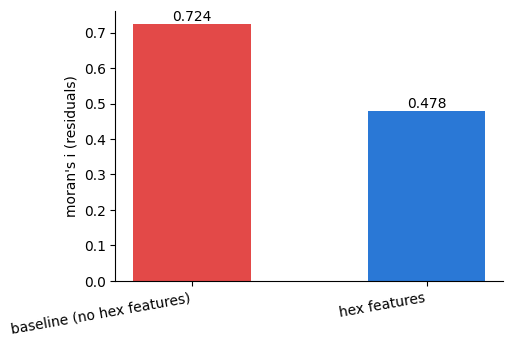

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(moran_df.index, moran_df["moran_i"], color=["#e34948", "#2a78d6"], width=0.5)
ax.set_ylabel("moran's i (residuals)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=10, ha="right")
for i, v in enumerate(moran_df["moran_i"]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

hex features cut moran's i roughly in half relative to a plain property+distance baseline, both still significant at p=0.001. this specific check uses a fixed linear model on purpose (baseline vs. +hex features only) so it isolates what the *hex features themselves* do, independent of which model fits them or what else gets added later.

### how much is left with the actual best model?

the check above intentionally holds the model fixed (linear) to isolate the hex features. this one instead takes the current best model (xgboost, full research feature set) and asks the same question: how spatially clustered are *its* out-of-fold residuals?

In [7]:
X_research, y = models.make_frame(df, models.RESEARCH_NUMERIC)
resid_full = models.out_of_fold_residuals(df, X_research, y, models.RESEARCH_NUMERIC, pipeline_fn=models.xgb_pipeline)

from src.spatial_diagnostics import morans_i_on_residuals
m_full = morans_i_on_residuals(df.assign(_resid=resid_full), "_resid")
print(f"moran's i, full model residuals: {m_full.I:.3f} (p={m_full.p_sim})")

('WARNING: ', '88195d344bfffff', ' is an island (no neighbors)')
moran's i, full model residuals: 0.244 (p=0.001)


/Users/cam/Documents/datascience/cv_projects/house_price_prediction/house_price_prediction_venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There is 1 island with id: 88195d344bfffff.
  warnings.warn(message)


down to roughly a third of the original no-hex-features baseline (0.72 -> ~0.26) once every engineered feature and the stronger model are both in play -- a much bigger reduction than the hex-only linear check shows on its own, since the extra features (res-9 hex, target encoding, street-level data) and xgboost's ability to combine them nonlinearly are both doing real additional work. still significant at p=0.001, so still not fully solved -- consistent with `PLAN.md`'s GWR experiment, which tried to close this specific gap further and didn't clear the bar (documented there as a tried-and-rejected result, not silently dropped).

## shap: what's driving xgboost's predictions

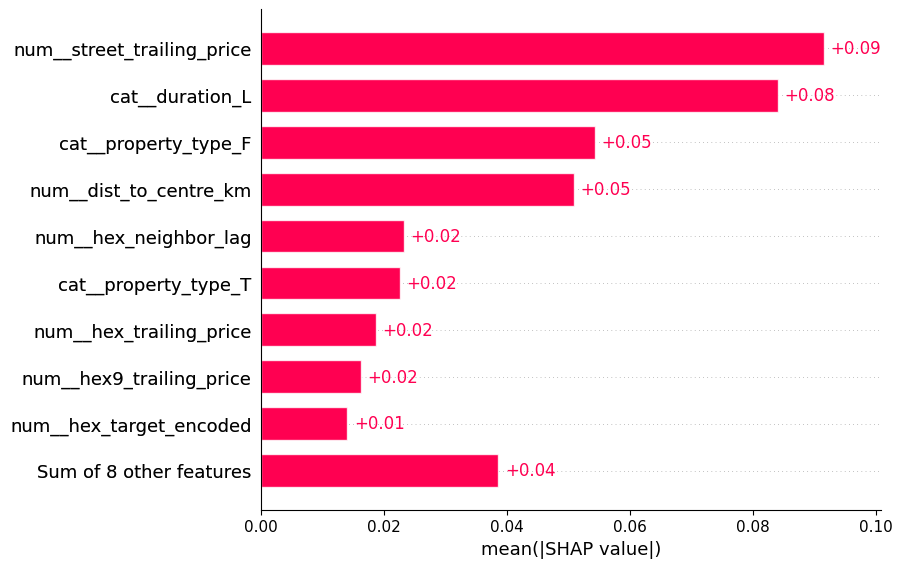

In [8]:
exp = models.shap_summary(df)
shap.plots.bar(exp)

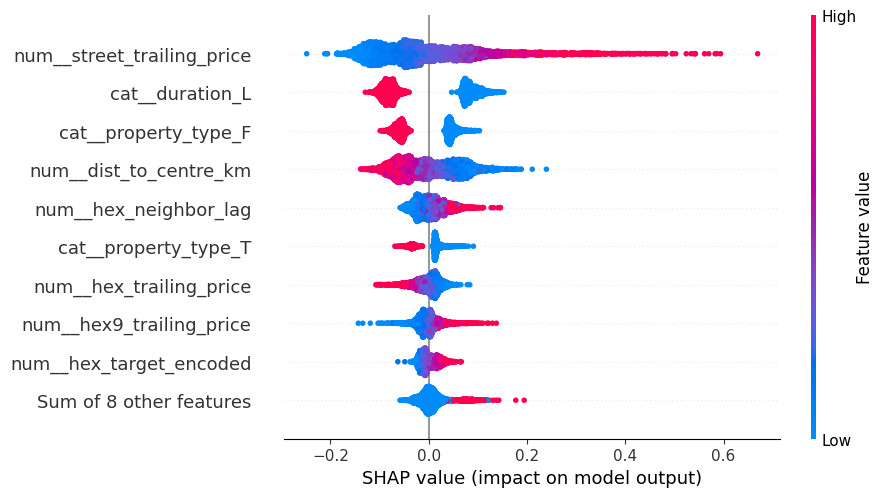

In [9]:
shap.plots.beeswarm(exp)

tenure, distance-to-centre, and property type still dominate, but the street-level and target-encoded hex features now sit among the top drivers too -- consistent with the r² lift from `PLAN.md`'s improvement audit, where street-level features were the single biggest addition. this uses the full research feature set (`shap_summary` defaults to `models.RESEARCH_NUMERIC`), so it includes the street/named-property features the deployed tool doesn't have access to.

## prediction intervals

`predict.py` doesn't just return a point estimate -- it also returns an 80% interval from two extra xgboost models trained with a quantile loss (`reg:quantileerror`, alpha 0.1 and 0.9). checking whether that interval is honest, not just decorative: what fraction of true out-of-fold prices actually fall inside it, on the same spatial cv used everywhere else.

In [10]:
X_serving, y = models.make_frame(df, models.SERVING_NUMERIC)
interval_metrics = models.evaluate_interval_cv(df, X_serving, y, models.SERVING_NUMERIC)
interval_metrics

{'empirical_coverage': np.float64(0.7794458613258839),
 'target_coverage': 0.8,
 'mean_interval_width_log10': np.float32(0.32577297)}

measured coverage sits close to the 80% target -- good enough that there's no immediate need to reach for a conformal-calibration library (`mapie`) on top of this, per the threshold set in `PLAN.md` (coverage would need to fall meaningfully below 70% to justify that). the interval itself is fairly wide in absolute terms (see `03_predict.ipynb` for example £ ranges) -- an honest reflection of r² still being well short of 1, not a bug in the interval itself.